# Lab 4-04：圖檢索 vs 向量檢索——同一組題目比一比

**目標**：用 14 題（4 題單跳、10 題多跳）同時考向量 RAG 和圖檢索，分開量「檢索有沒有撈到答案」和「最後答得對不對」，
畫成長條圖，然後討論什麼時候該用哪一個。

**你會學到**
- 評估要把「檢索」和「生成」拆開量，才知道錯在哪一段
- 向量檢索在多跳題上輸在哪裡
- 圖檢索的盲點：schema 沒涵蓋的事，它一個字都答不出來

**前置**：先讀 `00_concepts.md` 第 7 節。Lab 4-01、4-02（會 import 同資料夾的 `graph_retrieval.py`）；Ollama 有 `qwen2.5:3b` 與 `bge-m3`；
向量庫用模組 3 的 Chroma（`uv sync --group m3 --group m4`）。跑完約 5～10 分鐘。不需要 Neo4j。

**對應投影片**：「向量 RAG 答不了的兩種題」「GraphRAG 兩派分清」「GraphRAG 四種查詢模式」「選型：圖資料庫與 GraphRAG」「模組四 面試題」

![向量檢索與圖檢索的比較流程](images/graph_vs_vector.jpg)

*圖：同一個問題走兩條路。上排是向量檢索（撈最像的幾段原文），下排朱紅色是圖檢索（找實體、走多跳子圖）；兩邊都交給同一個 LLM、同一個 prompt，最後比正確率。*

## Step 1：題目

每題附上「答案關鍵字」：回答裡出現關鍵字就算對。這種評分很粗，但對短答案夠用，而且完全不用花 LLM 呼叫。

In [1]:
import json
from pathlib import Path

questions = json.loads(Path("data/questions.json").read_text(encoding="utf-8"))
for q in questions:
    print(f"{q['id']}  [{q['type']:6}] {q['question']}  → {q['answer_keywords']}")

q01  [single] 索隆的夢想是什麼？  → ['大劍豪']
q02  [single] 喬巴吃了什麼果實？  → ['人人果實']
q03  [single] 羅賓出身哪裡？  → ['歐哈拉']
q04  [single] 娜美在船上負責什麼工作？  → ['航海士']
q05  [multi ] 和索隆同一個海賊團的船長，夢想是什麼？  → ['海賊王']
q06  [multi ] 騙人布的父親是哪個海賊團的成員？  → ['紅髮海賊團']
q07  [multi ] 騙人布的父親所在海賊團的船長是誰？  → ['香克斯']
q08  [multi ] 魯夫的結拜哥哥是哪個海賊團的人？  → ['白鬍子海賊團']
q09  [multi ] 魯夫的結拜哥哥所屬海賊團的船長吃了什麼果實？  → ['震震果實']
q10  [multi ] 打倒阿龍的人，夢想是什麼？  → ['海賊王']
q11  [multi ] 巴托洛米奧所屬大船團的帶頭人，出身哪個村子？  → ['風車村']
q12  [multi ] 擁有和道一文字的草帽海賊團成員，夢想是什麼？  → ['大劍豪']
q13  [multi ] 新巨兵海賊團船長的弟弟，他的父親是誰？  → ['哈拉爾德']
q14  [multi ] 和東利一起擔任巨兵海賊團船長的人是誰？  → ['布洛基']


多跳題刻意設計成：答案需要的事實分散在兩三段裡，而且**最後那一段不會提到問題裡的人名**。
例如 q07「騙人布的父親所在海賊團的船長」，香克斯是船長這件事，寫在一段完全沒提到騙人布的文字裡。
q13、q14 是第 34 段艾爾巴夫的題目，還帶著一個陷阱：「巨兵海賊團」（東利、布洛基）和「新巨兵海賊團」（海爾丁）是兩個不同的海賊團。

## Step 2：向量 RAG（Chroma）

跟模組 3 一樣：切塊、用 bge-m3 算向量、放進 Chroma，問題進來取最像的 5 塊。
每段摘要有一千多字，整段塞 3 段就超過 3B 模型的 context（Ollama 預設 4096 token），所以按空行切成小段，每塊兩三百字。

In [2]:
import re

import chromadb
import numpy as np

from course_utils.llm import embed

text = Path("data/one_piece_summaries.md").read_text(encoding="utf-8")
chunks = []
for block in re.split(r"^## ", text, flags=re.M)[1:]:
    head, _, body = block.partition("\n")
    pid, title = head.split(maxsplit=1)
    for k, piece in enumerate(p for p in body.split("\n\n") if p.strip()):
        chunks.append({"id": f"{pid}-{k:02d}", "paragraph": pid, "title": title, "text": piece.strip()})

texts = [c["text"] for c in chunks]
vectors = [v for i in range(0, len(texts), 32) for v in embed(texts[i:i + 32])]  # 分批算，每批 32 塊

collection = chromadb.EphemeralClient().get_or_create_collection("one_piece", metadata={"hnsw:space": "cosine"})
collection.add(
    ids=[c["id"] for c in chunks],
    documents=texts,
    embeddings=vectors,
    metadatas=[{"paragraph": c["paragraph"], "title": c["title"]} for c in chunks],
)
print(f"{len(chunks)} 塊放進 Chroma")


def vector_search(question: str, k: int = 5) -> list[dict]:
    res = collection.query(query_embeddings=embed([question]), n_results=k)
    return [{"id": i, "text": doc, **meta, "score": 1 - dist}
            for i, doc, meta, dist in zip(res["ids"][0], res["documents"][0], res["metadatas"][0], res["distances"][0])]


def vector_context(question: str) -> str:
    return "\n\n".join(h["text"] for h in vector_search(question))


for hit in vector_search("騙人布的父親所在海賊團的船長是誰？"):
    print(f"{hit['score']:.3f}  [{hit['id']}] {hit['title']}：{hit['text'][:40]}…")

312 塊放進 Chroma
0.732  [10-00] 說謊的狙擊手：騙人布出身西羅布村，是草帽海賊團的狙擊手，彈弓打得極準。他常說大話，但夢想是成為…
0.640  [10-05] 說謊的狙擊手：戰後，騙人布海賊團宣布解散，三個小孩哭著送別。可雅為了報答，把家裡的一艘帆船黃金…
0.612  [25-06] 水之七島與司法島：佛朗基用珍貴的寶樹亞當木材，為他們造了一艘新船千陽號。騙人布向大家低頭道歉，回到…
0.595  [34-01] 巨人島艾爾巴夫：對騙人布來說，這座島有特別的意義。很久以前，在偉大航路的小花園，他遇見兩位決鬥了…
0.584  [33-03] 蛋頭島：島上還有一位重要人物：珠寶·波妮。她是波妮海賊團的船長，吃了年齡果實，能改變自己…


撈到的多半是騙人布和耶穌布的小段。香克斯是紅髮海賊團船長的那幾塊（02「紅髮與草帽」、11「紅髮海賊團的槍手」）
通常排不進前 5：它們講的是斷臂、草帽和四皇，跟「騙人布、父親」不像。`score` 是 1 減 cosine 距離，越大越像。

## Step 3：圖檢索

直接用上一本寫好的函式：找實體 → 剪枝走訪 4 步 → 念成句子。

In [3]:
from graph_retrieval import graph_context, link_entities, load_graph

G = load_graph()
q = "騙人布的父親所在海賊團的船長是誰？"
print("起點：", link_entities(G, q))
ctx = graph_context(G, q)
print(f"上下文 {len(ctx.splitlines())} 句，前 15 句：")
print("\n".join(ctx.splitlines()[:15]))

起點： ['騙人布']
上下文 62 句，前 15 句：
騙人布 出身 西羅布村
騙人布 是 草帽海賊團 的成員
騙人布 的夢想是 勇敢的海上戰士
騙人布 的父親是 耶穌布
騙人布 打倒了 佩羅娜
騙人布 打倒了 砂糖
草帽海賊團 擁有 黃金梅利號
草帽海賊團 擁有 千陽號
魯夫 是 草帽海賊團 的船長（帶頭的人）
耶穌布 是 紅髮海賊團 的成員
佩羅娜 擁有 幽靈果實
魯夫 出身 風車村
魯夫 擁有 橡膠果實
魯夫 擁有 草帽
魯夫 的夢想是 海賊王


## Step 4：先只比檢索——答案有沒有在上下文裡？

生成之前先問一個更基本的問題：**給 LLM 的資料裡，到底有沒有答案？**
沒有的話，LLM 再聰明也答不對（或只能靠瞎猜）。這一步完全不用呼叫 LLM。

In [4]:
def contains_answer(context: str, q: dict) -> bool:
    return any(kw in context for kw in q["answer_keywords"])


rows = []
for q in questions:
    v_ctx, g_ctx = vector_context(q["question"]), graph_context(G, q["question"])
    rows.append({"id": q["id"], "type": q["type"], "question": q["question"],
                 "v_ctx": v_ctx, "g_ctx": g_ctx,
                 "v_hit": contains_answer(v_ctx, q), "g_hit": contains_answer(g_ctx, q)})

print("題號   類型    向量  圖")
for r in rows:
    print(f"{r['id']}   {r['type']:6}  {'O' if r['v_hit'] else 'X'}     {'O' if r['g_hit'] else 'X'}")

題號   類型    向量  圖
q01   single  O     O
q02   single  O     O
q03   single  O     O
q04   single  O     X
q05   multi   O     O
q06   multi   X     O
q07   multi   X     O
q08   multi   X     O
q09   multi   X     O
q10   multi   X     O
q11   multi   X     O
q12   multi   O     O
q13   multi   X     O
q14   multi   O     O


注意兩件事：

- 向量檢索的 X 幾乎都在多跳題：鏈條的後半段不像問題，排不進前 5。
- 圖檢索的 X 在 q04「娜美在船上負責什麼工作」：我們的 schema 根本沒有「職位」這種關係，抽三元組時就丟掉了。
  **圖只知道你設計它知道的事。**

## Step 5：端到端——讓 LLM 回答

兩邊用同一個 prompt、同一個模型，只差上下文。Ollama 同時有很多人在用時回應會慢，這裡直接用 OpenAI SDK、給長一點的逾時。

In [5]:
import os

from openai import OpenAI

client = OpenAI(base_url=os.getenv("LOCAL_BASE_URL", "http://localhost:11434/v1"), api_key="ollama", timeout=300)
MODEL = os.getenv("LOCAL_MODEL", "qwen2.5:3b")


def chat(messages: list[dict]) -> str:
    return client.chat.completions.create(model=MODEL, messages=messages, temperature=0).choices[0].message.content


ANSWER_SYSTEM = "只根據提供的資料回答，用一句話。資料沒有就說「資料不足」。"


def answer(context: str, question: str) -> str:
    return chat([
        {"role": "system", "content": ANSWER_SYSTEM},
        {"role": "user", "content": f"資料：\n{context}\n\n問題：{question}"},
    ])


for r, q in zip(rows, questions):
    r["v_ans"] = answer(r["v_ctx"], q["question"])
    r["g_ans"] = answer(r["g_ctx"], q["question"])
    r["v_ok"] = contains_answer(r["v_ans"], q)
    r["g_ok"] = contains_answer(r["g_ans"], q)
    print(f"{r['id']} {q['question']}")
    print(f"   向量 {'O' if r['v_ok'] else 'X'}：{r['v_ans'][:60]}")
    print(f"   圖   {'O' if r['g_ok'] else 'X'}：{r['g_ans'][:60]}")

q01 索隆的夢想是什麼？
   向量 O：索隆的夢想是成為世界第一大劍豪。
   圖   O：索隆的夢想是世界第一大劍豪。
q02 喬巴吃了什麼果實？
   向量 O：喬巴吃了人人果實。
   圖   O：喬巴吃了人人果實。
q03 羅賓出身哪裡？
   向量 O：羅賓出身於歐哈拉。
   圖   O：羅賓出身於歐哈拉。
q04 娜美在船上負責什麼工作？
   向量 O：娜美在船上负责航海士的工作，包括看天氣、画海图，并且梦想亲自绘制世界地图。
   圖   X：資料不足。
q05 和索隆同一個海賊團的船長，夢想是什麼？
   向量 X：佛朗基是草帽海賊團的船匠，夢想是讓船團的新船千陽號能夠長久航行。
   圖   O：魯夫是草帽海賊團的船長，他的夢想是海賊王。因此，和索隆同一個海賊團的船長，夢想是海賊王。
q06 騙人布的父親是哪個海賊團的成員？
   向量 X：騙人布的父親是耶穌布，他很早就離開村子上了海賊船。
   圖   O：騙人布的父親是耶穌布，他是紅髮海賊團的成員。
q07 騙人布的父親所在海賊團的船長是誰？
   向量 X：騙人布的父親所在海賊團的船長是東利與布洛基。
   圖   O：騙人布的父親耶穌布是紅髮海賊團的成員，而香克斯是紅髮海賈的船長。所以騙人布的父親所在海賊團的船長是香克斯。
q08 魯夫的結拜哥哥是哪個海賊團的人？
   向量 X：艾斯是火拳海賊團的人。
   圖   X：魯夫的結拜哥哥薩波屬於革命軍。
q09 魯夫的結拜哥哥所屬海賊團的船長吃了什麼果實？
   向量 X：魯夫的結拜哥哥薩波（小時候是艾斯）的結拜哥哥所屬海賊團的船長巴托洛米奧吃了能造出透明屏障的屏障果實。
   圖   X：薩波和艾斯的結拜哥哥香克斯所屬的草帽海賊團的船長香克斯擁有的果實是草帽。
q10 打倒阿龍的人，夢想是什麼？
   向量 X：打倒阿龍的人，夢想是奪回同伴。
   圖   O：魯夫 打倒了 阿龍，而魯夫的夢想是海賊王。因此，打倒阿龍的人，夢想是海賊王。
q11 巴托洛米奧所屬大船團的帶頭人，出身哪個村子？
   向量 X：巴托洛米奧出身東海。
   圖   O：巴托洛米奧出身東海，而草帽大船團的帶頭人魯夫出身風車村，所以無法直接回答巴托洛米奧出身哪個村子。資料中沒有提供這方面的信
q12 擁有和道一文字的草帽海賊團成員，夢想是什麼？
   向量 

逐題讀一下，幾個值得注意的地方（以存檔那次的輸出為準）：

- **q07 向量**答「東利與布洛基」：撈到的第 34 段講騙人布在小花園遇到兩位巨兵海賊團的船長，模型就拿來湊答案。資料像，但不是問的那條鏈。
- **q11 圖**被判「對」，其實它說「資料不足」，只是句子裡順口提到「風車村」。關鍵字評分會被這種回答騙過，模組 8 會換成 LLM-as-a-judge。
- **q13 兩邊都錯**，圖的檢索卻是命中的。問題出在 schema：`BROTHER_OF` 被念成「是…的結拜哥哥」，可是海爾丁和洛基是同父異母的兄弟，不是結拜。
  關係標籤把語意壓縮掉了，念出來的句子又誤導了模型（見 `00_concepts.md`「常見坑」）。
- **q08、q09**：魯夫現在有兩個結拜哥哥（艾斯、薩波），題目本身變得有歧義，模型挑了薩波（革命軍）。出題時也要檢查語料更新後，題目還是不是只有一個答案。

## Step 6：畫出來

四組數字：向量／圖 × 檢索命中／回答正確，再分單跳、多跳。

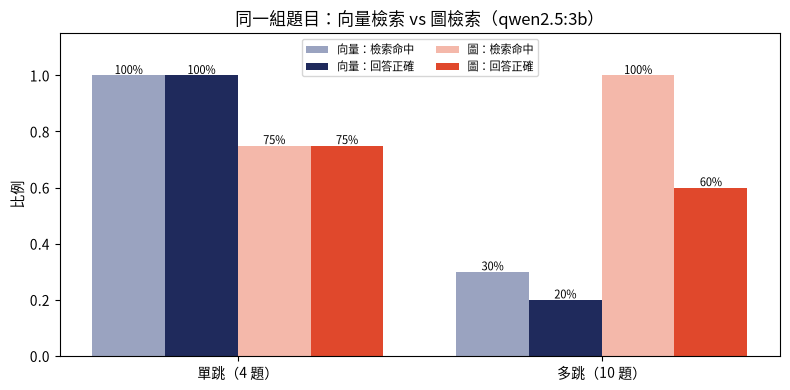

In [6]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()


def rate(key: str, kind: str) -> float:
    sel = [r for r in rows if r["type"] == kind]
    return sum(r[key] for r in sel) / len(sel)


groups = [f"單跳（{sum(r['type'] == 'single' for r in rows)} 題）", f"多跳（{sum(r['type'] == 'multi' for r in rows)} 題）"]
series = {
    "向量：檢索命中": ("v_hit", "#9aa3c0"),
    "向量：回答正確": ("v_ok", "#1f2a5c"),
    "圖：檢索命中": ("g_hit", "#f4b8aa"),
    "圖：回答正確": ("g_ok", "#e0482c"),
}
x = np.arange(len(groups))
fig, ax = plt.subplots(figsize=(8, 4))
for i, (name, (key, color)) in enumerate(series.items()):
    vals = [rate(key, "single"), rate(key, "multi")]
    bars = ax.bar(x + (i - 1.5) * 0.2, vals, width=0.2, label=name, color=color)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], fontsize=8)
ax.set_xticks(x, groups)
ax.set_ylim(0, 1.15)
ax.set_ylabel("比例")
ax.set_title("同一組題目：向量檢索 vs 圖檢索（qwen2.5:3b）")
ax.legend(fontsize=8, ncol=2, loc="upper center")
plt.tight_layout()
plt.show()

再把每一題攤開，看錯在哪一格：

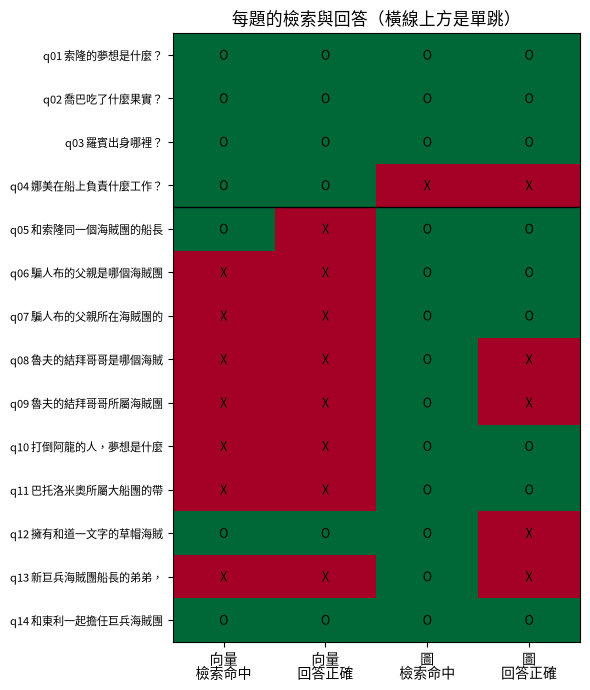

In [7]:
cols = ["v_hit", "v_ok", "g_hit", "g_ok"]
M = np.array([[r[c] for c in cols] for r in rows], dtype=float)
fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(M, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(4), ["向量\n檢索命中", "向量\n回答正確", "圖\n檢索命中", "圖\n回答正確"])
ax.set_yticks(range(len(rows)), [f"{r['id']} {r['question'][:12]}" for r in rows], fontsize=8)
for i in range(len(rows)):
    for j in range(4):
        ax.text(j, i, "O" if M[i, j] else "X", ha="center", va="center", fontsize=9)
ax.axhline(3.5, color="black", lw=1)
ax.set_title("每題的檢索與回答（橫線上方是單跳）")
plt.tight_layout()
plt.show()

讀這張圖的方法：

- **檢索 X、回答 X**：撈錯資料，怪檢索。
- **檢索 O、回答 X**：資料給了，模型沒串起來，怪生成（換大模型、改 prompt）。
- **檢索 X、回答 O**：要小心，模型可能是靠自己的知識猜中的，不是靠你的資料。

這就是評估要拆兩段量的原因：只看最後的正確率，你不知道該修哪裡。模組 8 會把這套做法變成固定的回歸評估。

## Step 7：什麼時候用哪一個？

把這一本看到的現象整理起來：

| 問題長什麼樣 | 建議 | 原因 |
|---|---|---|
| 答案寫在某一段裡，問法跟原文像（「索隆的夢想」） | 向量 | 便宜、不用建圖，單跳表現已經很好 |
| 要串好幾個實體（「A 的 B 的 C」） | 圖 | 沿著邊走，中間的段落不必「長得像問題」 |
| 問的是 schema 沒有的細節（職位、外號、場景描述） | 向量 | 圖只存你定義過的關係，其他資訊在抽取時就丟了 |
| 要看全貌（「故事裡有哪幾股勢力」） | GraphRAG Global Search | 兩者都撈不到；要先分群、寫社群報告再彙總（投影片「Global Search 社群報告」） |
| 資料常改、沒人維護 schema | 向量 | 建圖要抽取、正規化、人工校對，維護成本高 |

實務上最常見的是**兩個一起用**：圖負責找到「相關的是誰」，再把這些實體出現的原文段落一起撈出來，
投影片「Local Search」就是這個組合。

## 試試看

1. 把 `vector_search` 的 `k` 從 5 改成 10，重跑 Step 4。多跳題的檢索命中率變多少？代價是什麼（上下文長度）？
2. 做一個混合版：上下文＝圖檢索的句子＋向量前 3 塊，重跑 Step 5。q04 和多跳題能不能都答對？
3. 自己出 2 題多跳題加進 `data/questions.json`（例如「打倒阿龍的人，擁有哪頂帽子？」），看看兩邊各表現如何。

## 小結

- 評估把檢索和生成拆開量：檢索命中率告訴你資料有沒有給到，回答正確率告訴你模型有沒有用好。
- 向量檢索在多跳題上輸在「鏈條後半段不像問題」；圖檢索輸在「schema 沒涵蓋的事」。兩者互補，常一起用。
- 模組 4 到這裡結束。模組 5 開始做 Agent：讓模型自己決定要不要查圖、查哪裡、查幾次，而不是由我們寫死的流程決定。